# TERZ net comparison: embeddings + density + clustering

For every (year, `ont`) combination this notebook:

1. loads the TERZ parquet, normalises each trigger by its max and standardises the features (same preprocessing as `net_compare_cut.ipynb`),
2. computes a t-SNE and a UMAP embedding (cached on disk, so the slow part only runs once),
3. draws **one 2x2 figure per projection**: embedding scatter, KDE density, DBSCAN, HDBSCAN (the logic of `density.ipynb`).

Half-width window is 12 s (`hw12`), as in `net_compare_cut.ipynb`.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
METRIC = "euclidean"

PARQUET_DIR = Path("year_TERZ_parquets")
CACHE_DIR = Path("TERZ_embeddings_cache")      # embeddings are stored here
CACHE_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("TERZ_figures_net_compare")
SAVE_FIGS = False                         # True -> also save every figure as a PNG in FIG_DIR

# What to run. net_compare_cut.ipynb only processed 2022; add the other years here.
YEARS = [2022]                            # e.g. [2022, 2023, 2024, 2025]
ONTS = [15, 20, 25]
HW = [1, 2, 4, 6, 12]                       

# t-SNE (same values as net_compare_cut.ipynb)
PERPLEXITY = 350
EARLY_EXAGGERATION = 14

# UMAP -- placeholders, set these to the values you used in mn-sena-splited.ipynb
UMAP_N_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1

# Clustering parameters, carried over from density.ipynb (see the note below the cell)
CLUSTER_PARAMS = {
    "tsne": {"dbscan_eps": 4, "dbscan_min_samples": 500, "hdbscan_min_samples": 500},
    "umap": {"dbscan_eps": 2, "dbscan_min_samples": 500, "hdbscan_min_samples": 500},
}
# Per-dataset overrides, keyed by (year, ont, projection), e.g.
# CLUSTER_OVERRIDES = {(2022, 15, "umap"): {"dbscan_eps": 1.5}}
CLUSTER_OVERRIDES = {}

# Density panel
DENSITY_3D = True                         # True: 3D surface as in density.ipynb, False: 2D filled contours
GRID_SIZE = 200                           # density.ipynb used 500; 200 is ~6x faster to evaluate

PROJECTIONS = {"tsne": "t-SNE", "umap": "UMAP"}

**Clustering parameters.** `eps`/`min_samples` come from `density.ipynb`, where they were tuned for the MN-SENA embeddings. t-SNE/UMAP coordinates change scale with the perplexity, the number of points and the data, so for these TERZ sets they will probably need adjusting (use `CLUSTER_OVERRIDES` per dataset). `min_samples=500` is also a large fraction of the smaller sets (the 2025 `ont=25` set has about 10k triggers).

In [3]:
def feature_matrix(year, ont, hw):
    """Load one parquet, normalise each row by its max and standardise (as in net_compare_cut.ipynb)."""
    path = PARQUET_DIR / f"TERZ_HHZ_hw{hw}_ont{ont}_{year}.parquet"
    df = pd.read_parquet(path)

    feature_columns = [col for col in df.columns if col.startswith("feature_")]
    if len(feature_columns) == 0:
        raise ValueError(f"No feature_* columns found in {path}.")

    X = df[feature_columns].to_numpy(dtype="float64")
    print(f"{year} ont={ont}: {X.shape[0]} triggers, {X.shape[1]} features")

    X_norm = X / X.max(axis=1, keepdims=True)
    return StandardScaler().fit_transform(X_norm)


def compute_tsne(X_scaled):
    return TSNE(n_components=2, perplexity=PERPLEXITY, early_exaggeration=EARLY_EXAGGERATION,
                init="pca", learning_rate="auto", random_state=RANDOM_STATE,
                metric=METRIC).fit_transform(X_scaled)


def compute_umap(X_scaled):
    import umap  # imported here so cached embeddings can be plotted without umap-learn
    return umap.UMAP(n_components=2, n_neighbors=UMAP_N_NEIGHBORS, min_dist=UMAP_MIN_DIST,
                     metric=METRIC, random_state=RANDOM_STATE).fit_transform(X_scaled)


COMPUTE = {"tsne": compute_tsne, "umap": compute_umap}


def cache_path(year, ont, projection):
    # the parameters are part of the file name, so changing them never reuses a stale embedding
    if projection == "tsne":
        tag = f"tsne_perp{PERPLEXITY}_ee{EARLY_EXAGGERATION}"
    else:
        tag = f"umap_nn{UMAP_N_NEIGHBORS}_md{UMAP_MIN_DIST}"
    return CACHE_DIR / f"TERZ_hw{hw}_ont{ont}_{year}_{tag}.npy"


def get_embeddings(year, ont, hw):
    """Return {"tsne": (n, 2), "umap": (n, 2)}; computes and caches whatever is missing."""
    paths = {proj: cache_path(year, ont, proj) for proj in COMPUTE}
    X_scaled = feature_matrix(year, ont, hw) if not all(p.exists() for p in paths.values()) else None

    embeddings = {}
    for proj, path in paths.items():
        if path.exists():
            embeddings[proj] = np.load(path)
            print(f"{year} ont={ont}: {PROJECTIONS[proj]} loaded from {path.name}")
        else:
            print(f"{year} ont={ont}: computing {PROJECTIONS[proj]} ...")
            embeddings[proj] = COMPUTE[proj](X_scaled)
            np.save(path, embeddings[proj])
    return embeddings

In [7]:
def density_surface(E, grid=None):
    """Gaussian KDE of the 2D embedding evaluated on a regular grid."""
    grid = grid or GRID_SIZE
    x, y = E[:, 0], E[:, 1]
    kde = gaussian_kde(np.vstack([x, y]))
    X, Y = np.meshgrid(np.linspace(x.min(), x.max(), grid), np.linspace(y.min(), y.max(), grid))
    Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)
    return X, Y, Z


def cluster_labels(E, params):
    dbscan = DBSCAN(eps=params["dbscan_eps"], min_samples=params["dbscan_min_samples"],
                    metric=METRIC).fit(E)
    hdbscan = HDBSCAN(min_samples=params["hdbscan_min_samples"], metric=METRIC, copy=True).fit(E)
    return dbscan.labels_, hdbscan.labels_


def plot_clusters(ax, E, labels, title, xlabel, ylabel):
    noise = labels == -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    ax.scatter(E[noise, 0], E[noise, 1], c="lightgray", s=8, alpha=0.5, label="noise")
    ax.scatter(E[~noise, 0], E[~noise, 1], c=labels[~noise], cmap="viridis", s=8, alpha=0.7)
    ax.set_title(f"{title}\n{n_clusters} clusters, {noise.sum()} noise points")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if noise.any():
        ax.legend(loc="best", markerscale=2)
    return n_clusters, int(noise.sum())


def plot_projection(E, proj, year, ont):
    """One figure: embedding | density | DBSCAN | HDBSCAN."""
    name = PROJECTIONS[proj]
    params = {**CLUSTER_PARAMS[proj], **CLUSTER_OVERRIDES.get((year, ont, proj), {})}
    xlabel, ylabel = f"{name} 1", f"{name} 2"

    db_labels, hdb_labels = cluster_labels(E, params)
    X, Y, Z = density_surface(E)

    fig = plt.figure(figsize=(16, 13))

    # 1) embedding
    ax = fig.add_subplot(2, 2, 1)
    ax.scatter(E[:, 0], E[:, 1], s=5, alpha=0.5)
    if proj == "tsne":
        ax.set_title(f"{name} | Perplexity = {PERPLEXITY} | Early Exaggeration = {EARLY_EXAGGERATION} | Metric = {METRIC}")
    else:
        ax.set_title(f"{name} | n_neighbors = {UMAP_N_NEIGHBORS} | min_dist = {UMAP_MIN_DIST} | Metric = {METRIC}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    # 2) density
    if DENSITY_3D:
        ax = fig.add_subplot(2, 2, 2, projection="3d")
        surf = ax.plot_surface(X, Y, Z, cmap="coolwarm", linewidth=0, antialiased=False)
        ax.set_zlabel("density")
    else:
        ax = fig.add_subplot(2, 2, 2)
        surf = ax.contourf(X, Y, Z, levels=30, cmap="coolwarm")
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, pad=0.1)
    ax.set_title(f"Gaussian KDE density on the {name} embedding")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    # 3) DBSCAN
    ax = fig.add_subplot(2, 2, 3)
    n_db, noise_db = plot_clusters(
        ax, E, db_labels,
        f"DBSCAN (eps={params['dbscan_eps']}, min_samples={params['dbscan_min_samples']})",
        xlabel, ylabel)

    # 4) HDBSCAN
    ax = fig.add_subplot(2, 2, 4)
    n_hdb, noise_hdb = plot_clusters(
        ax, E, hdb_labels,
        f"HDBSCAN (min_samples={params['hdbscan_min_samples']})",
        xlabel, ylabel)

    fig.suptitle(f"{year} | ont={ont} | {name} | {E.shape[0]} triggers", fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.97])

    if SAVE_FIGS:
        FIG_DIR.mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / f"TERZ_hw12_ont{ont}_{year}_{proj}.png", dpi=150)
    plt.show()
    plt.close(fig)

    print(f"{year} ont={ont} {name}: DBSCAN {n_db} clusters / {noise_db} noise, "
          f"HDBSCAN {n_hdb} clusters / {noise_hdb} noise")


def run(year, ont, hw):
    embeddings = get_embeddings(year, ont, hw)
    for proj in PROJECTIONS:
        plot_projection(embeddings[proj], proj, year, ont)

## Run

Loops over `YEARS` x `ONTS`. To look at a single case, call e.g. `run(2022, 20)` instead.

2022 ont=15: 49599 triggers, 1230 features
2022 ont=15: computing t-SNE ...
2022 ont=15: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


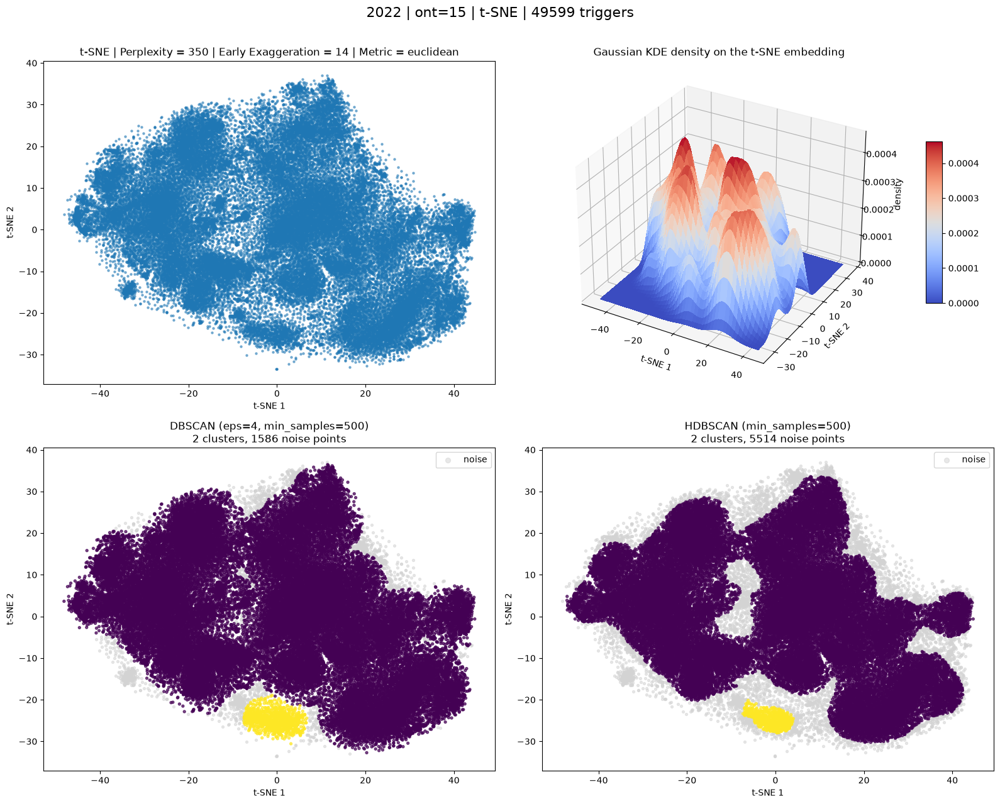

2022 ont=15 t-SNE: DBSCAN 2 clusters / 1586 noise, HDBSCAN 2 clusters / 5514 noise


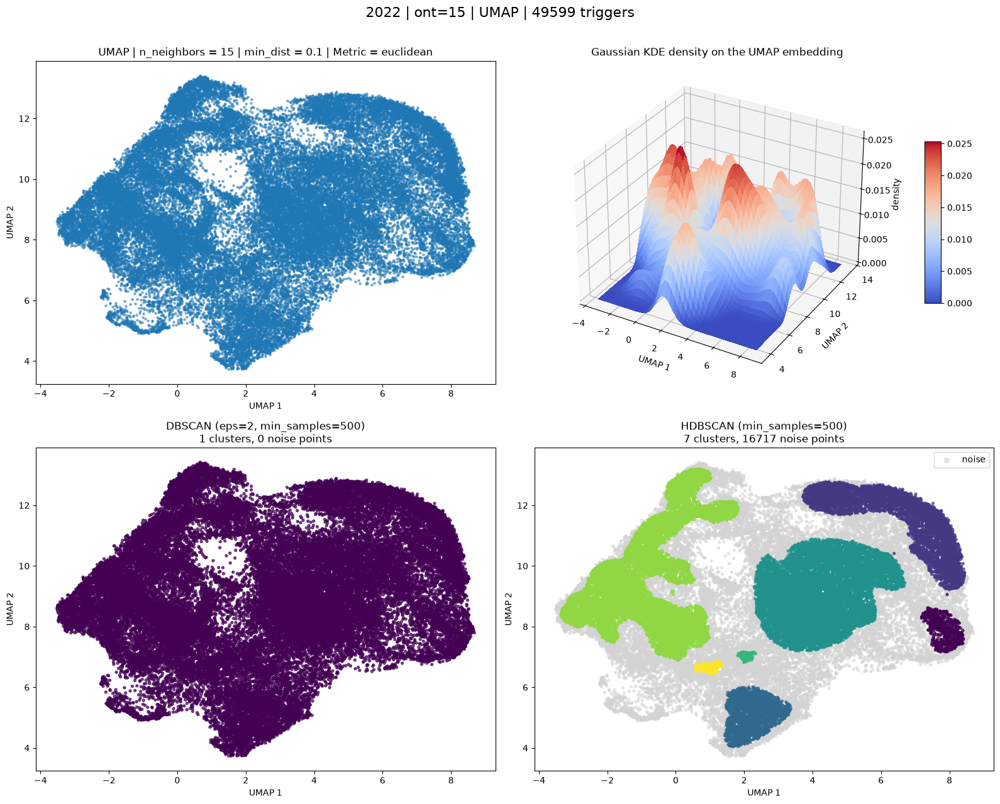

2022 ont=15 UMAP: DBSCAN 1 clusters / 0 noise, HDBSCAN 7 clusters / 16717 noise
2022 ont=15: 49599 triggers, 1230 features
2022 ont=15: computing t-SNE ...
2022 ont=15: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


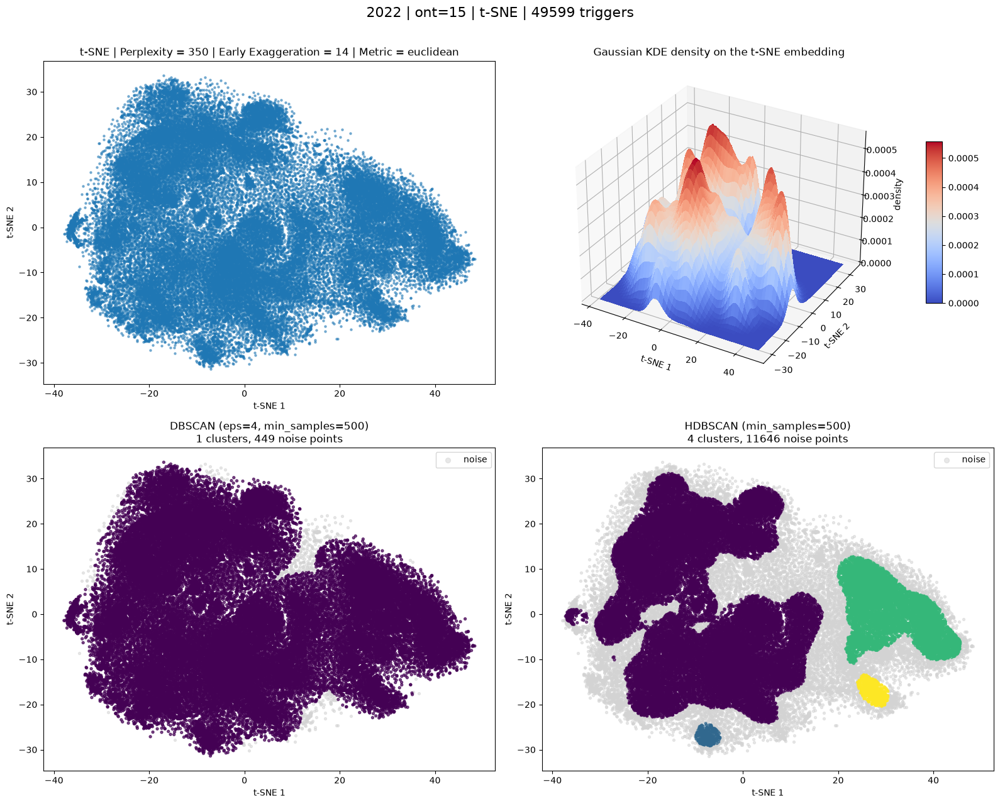

2022 ont=15 t-SNE: DBSCAN 1 clusters / 449 noise, HDBSCAN 4 clusters / 11646 noise


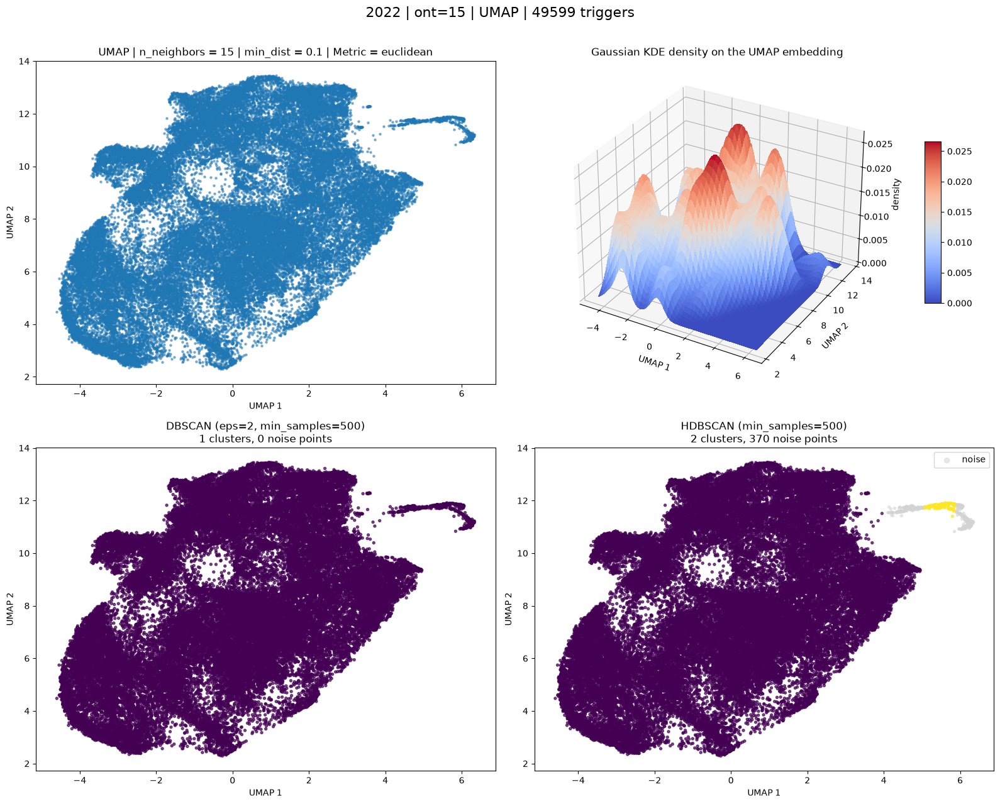

2022 ont=15 UMAP: DBSCAN 1 clusters / 0 noise, HDBSCAN 2 clusters / 370 noise
2022 ont=15: 49599 triggers, 1230 features
2022 ont=15: computing t-SNE ...
2022 ont=15: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


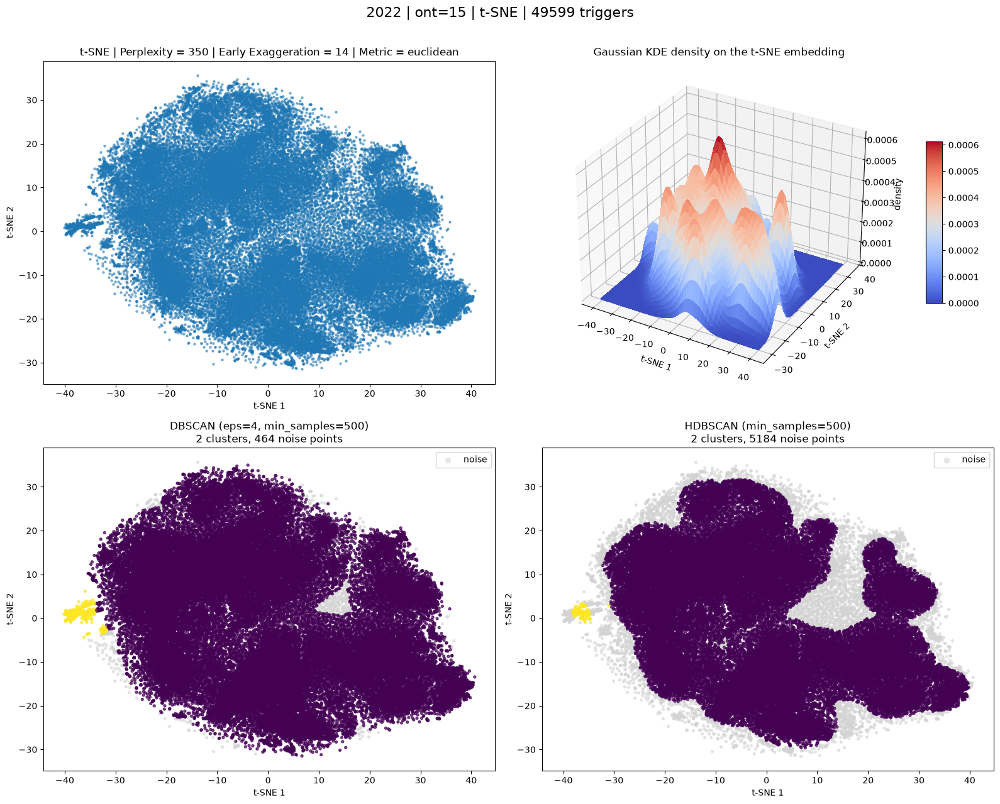

2022 ont=15 t-SNE: DBSCAN 2 clusters / 464 noise, HDBSCAN 2 clusters / 5184 noise


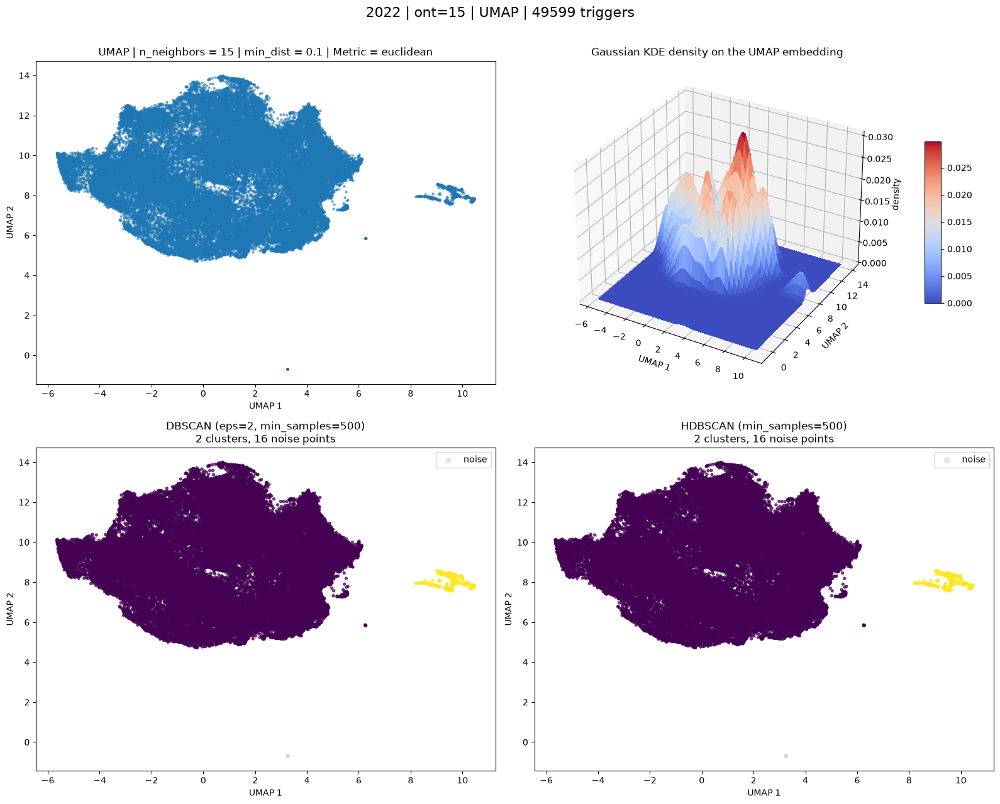

2022 ont=15 UMAP: DBSCAN 2 clusters / 16 noise, HDBSCAN 2 clusters / 16 noise
2022 ont=15: 49599 triggers, 1230 features
2022 ont=15: computing t-SNE ...
2022 ont=15: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


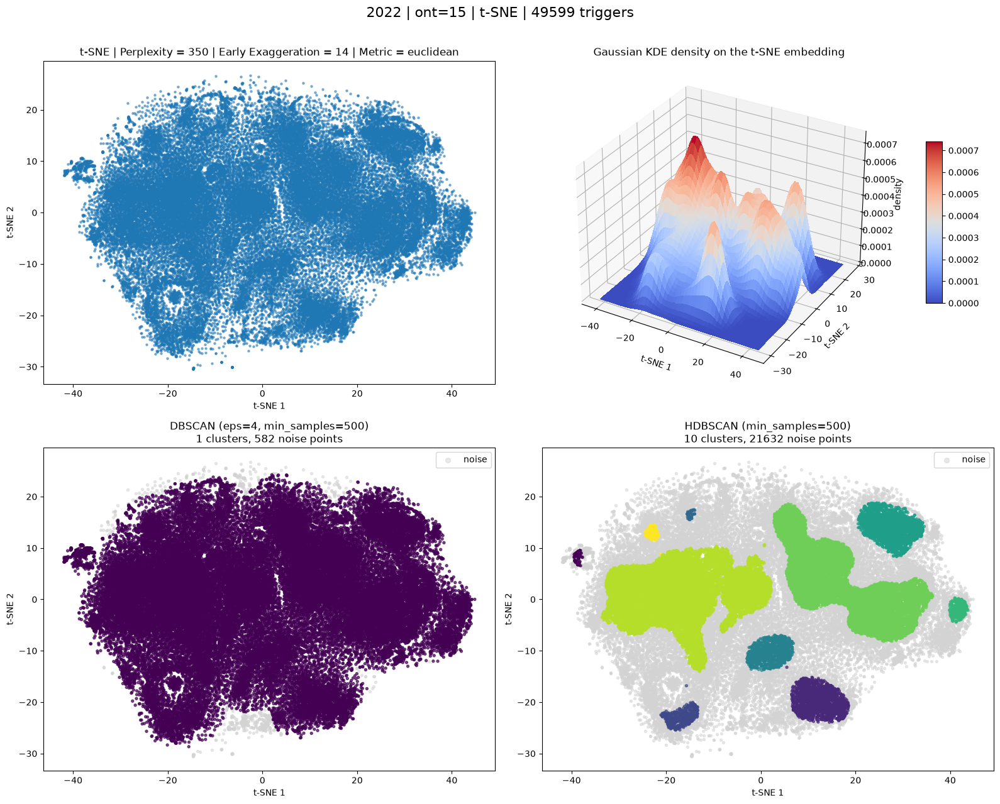

2022 ont=15 t-SNE: DBSCAN 1 clusters / 582 noise, HDBSCAN 10 clusters / 21632 noise


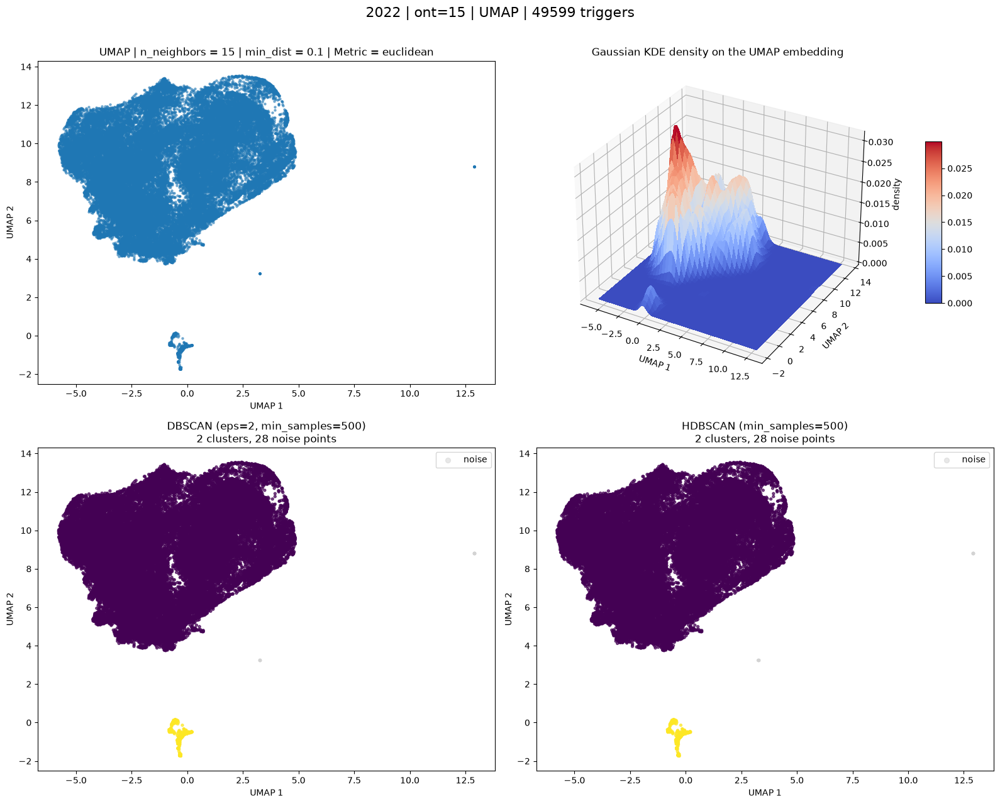

2022 ont=15 UMAP: DBSCAN 2 clusters / 28 noise, HDBSCAN 2 clusters / 28 noise
2022 ont=15: 49599 triggers, 1230 features
2022 ont=15: computing t-SNE ...
2022 ont=15: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


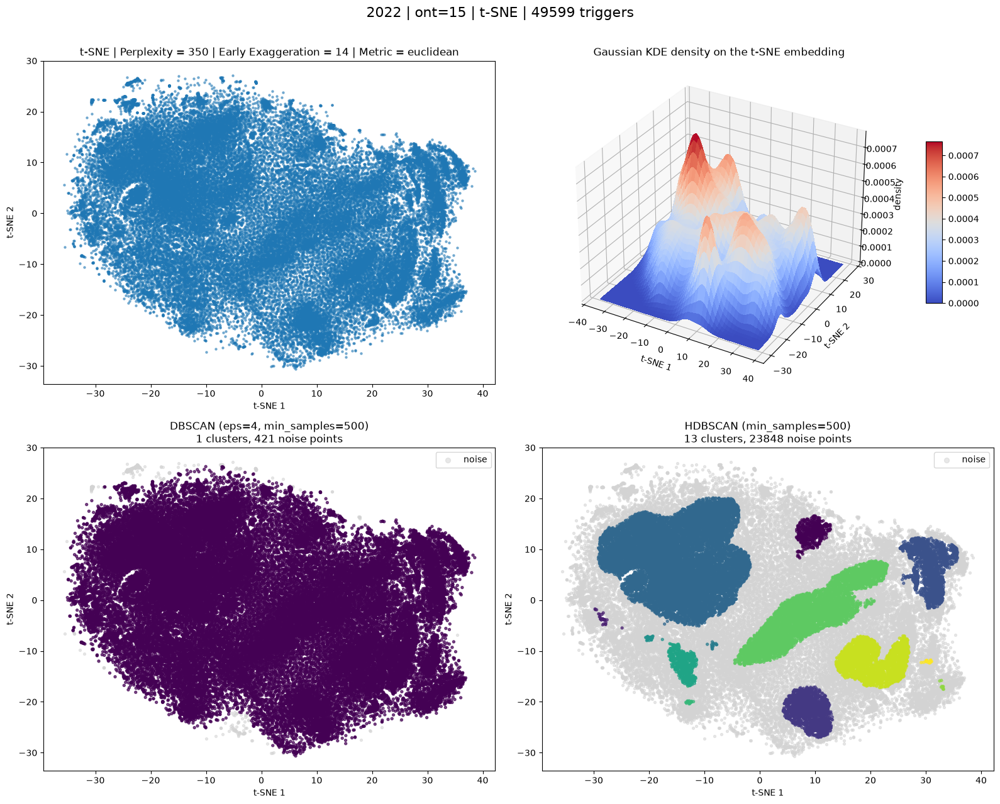

2022 ont=15 t-SNE: DBSCAN 1 clusters / 421 noise, HDBSCAN 13 clusters / 23848 noise


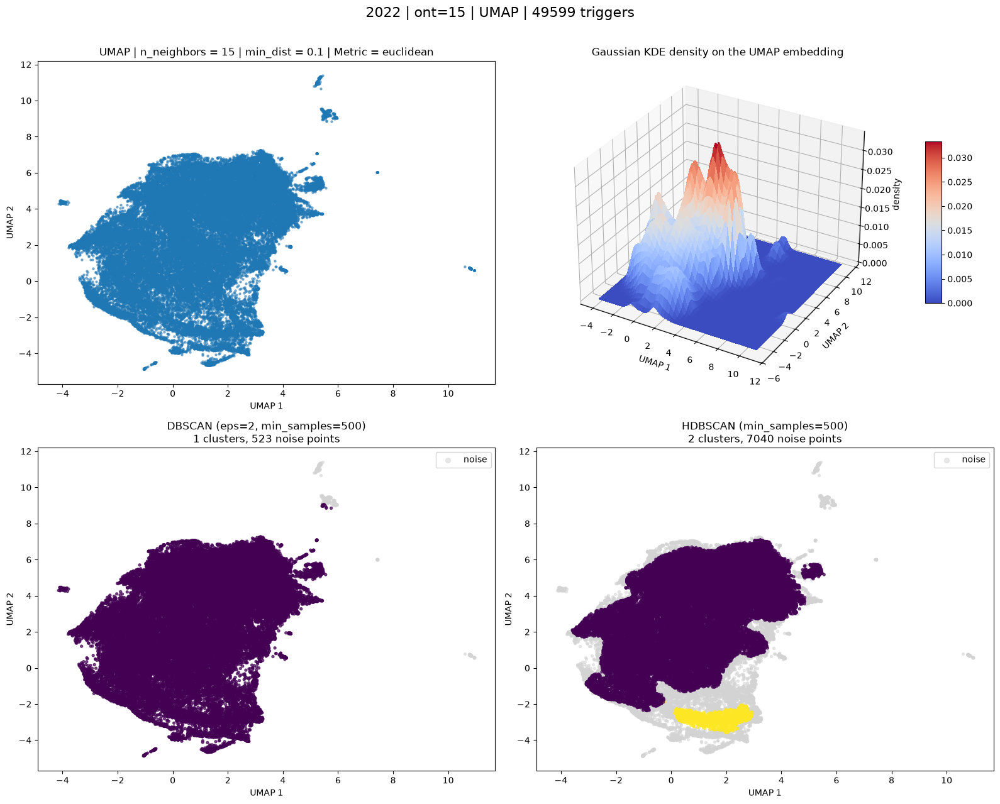

2022 ont=15 UMAP: DBSCAN 1 clusters / 523 noise, HDBSCAN 2 clusters / 7040 noise
2022 ont=20: 30941 triggers, 1230 features
2022 ont=20: computing t-SNE ...
2022 ont=20: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


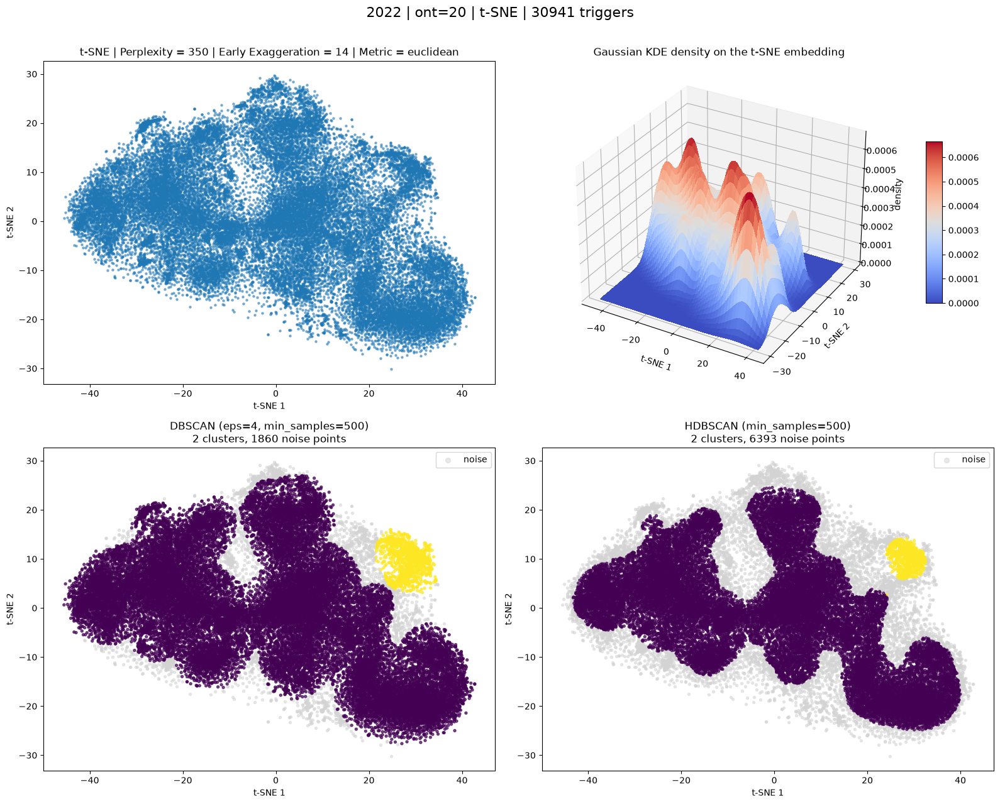

2022 ont=20 t-SNE: DBSCAN 2 clusters / 1860 noise, HDBSCAN 2 clusters / 6393 noise


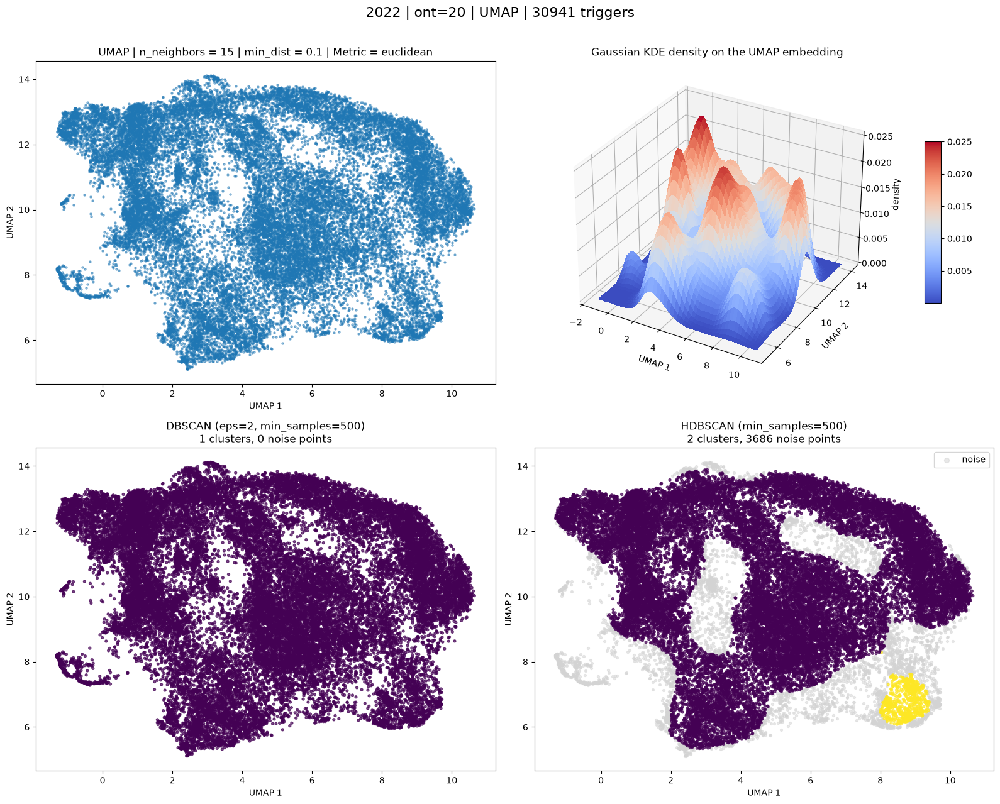

2022 ont=20 UMAP: DBSCAN 1 clusters / 0 noise, HDBSCAN 2 clusters / 3686 noise
2022 ont=20: 30941 triggers, 1230 features
2022 ont=20: computing t-SNE ...
2022 ont=20: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


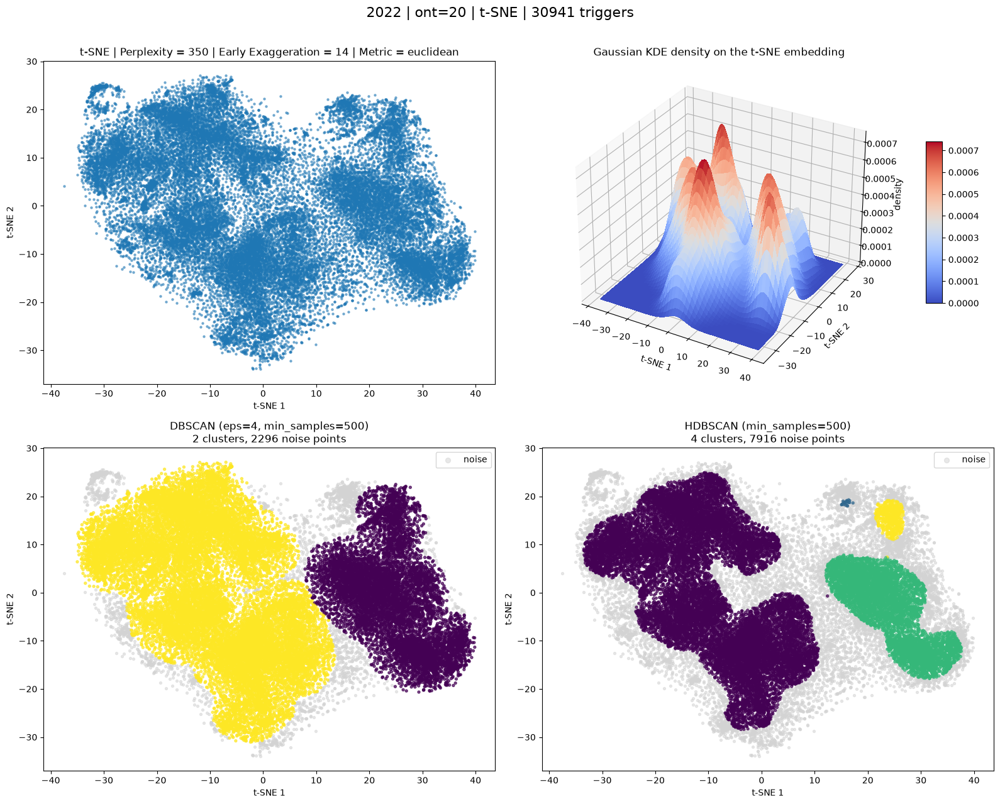

2022 ont=20 t-SNE: DBSCAN 2 clusters / 2296 noise, HDBSCAN 4 clusters / 7916 noise


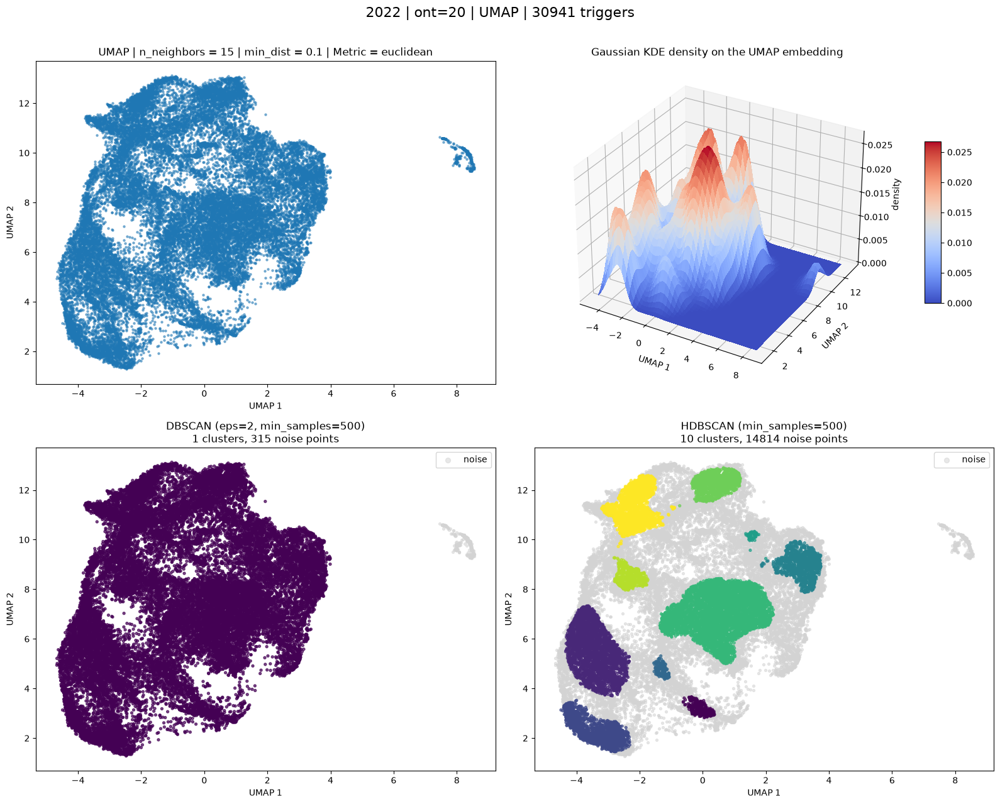

2022 ont=20 UMAP: DBSCAN 1 clusters / 315 noise, HDBSCAN 10 clusters / 14814 noise
2022 ont=20: 30941 triggers, 1230 features
2022 ont=20: computing t-SNE ...
2022 ont=20: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


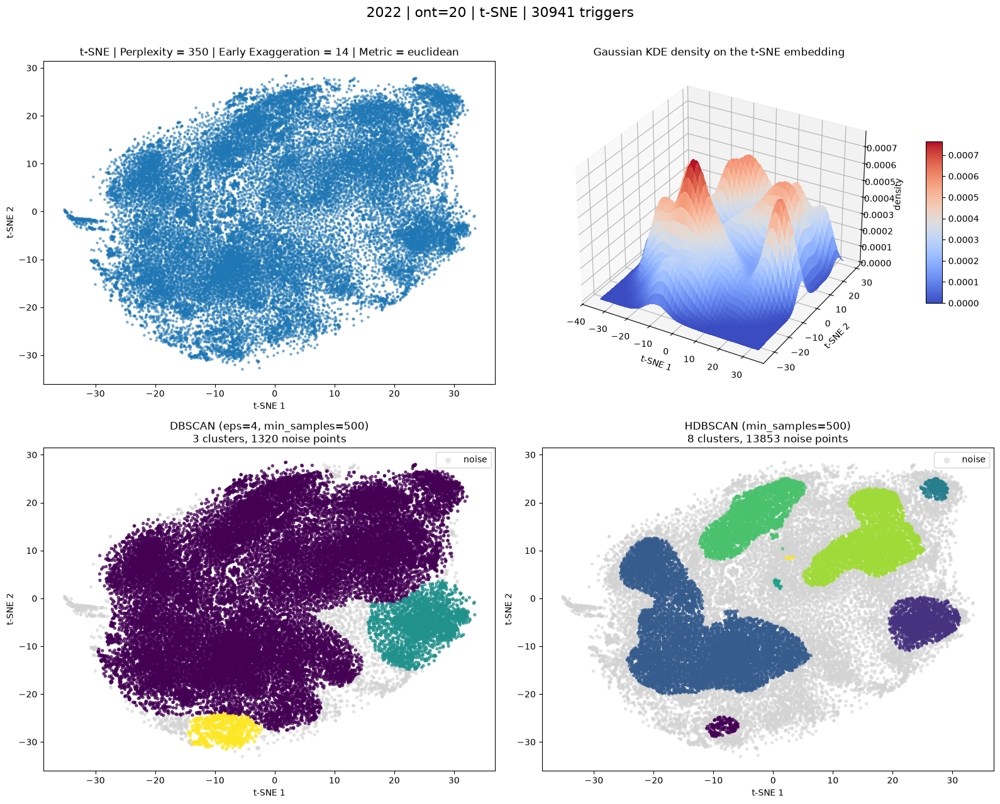

2022 ont=20 t-SNE: DBSCAN 3 clusters / 1320 noise, HDBSCAN 8 clusters / 13853 noise


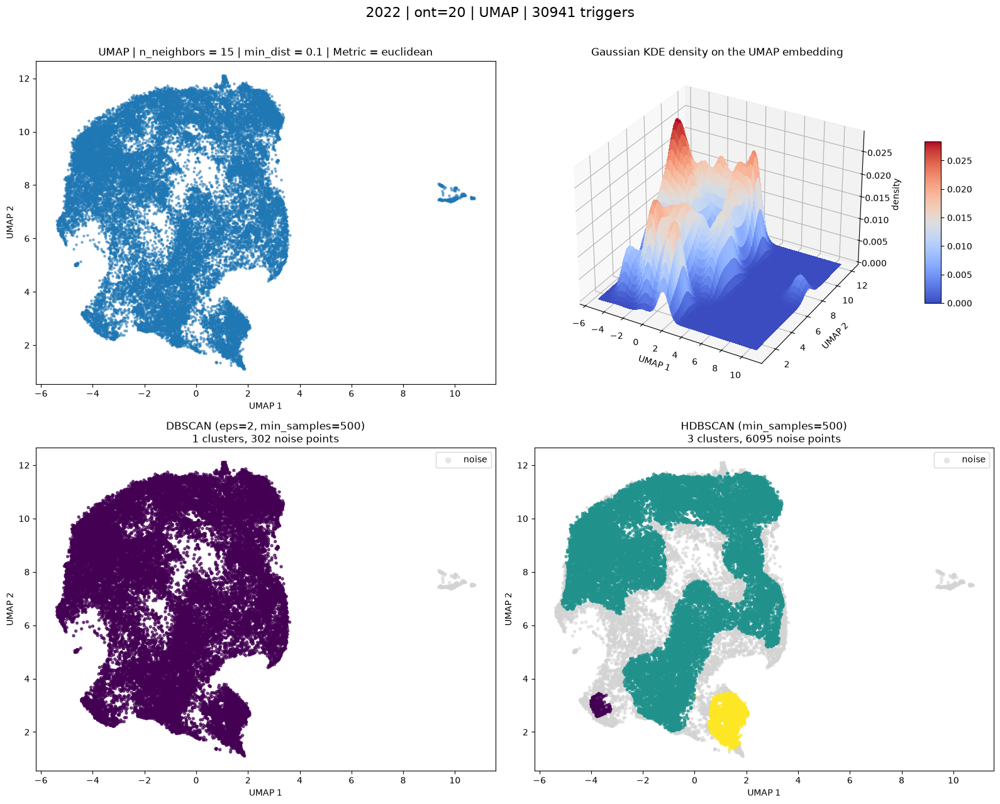

2022 ont=20 UMAP: DBSCAN 1 clusters / 302 noise, HDBSCAN 3 clusters / 6095 noise
2022 ont=20: 30941 triggers, 1230 features
2022 ont=20: computing t-SNE ...
2022 ont=20: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


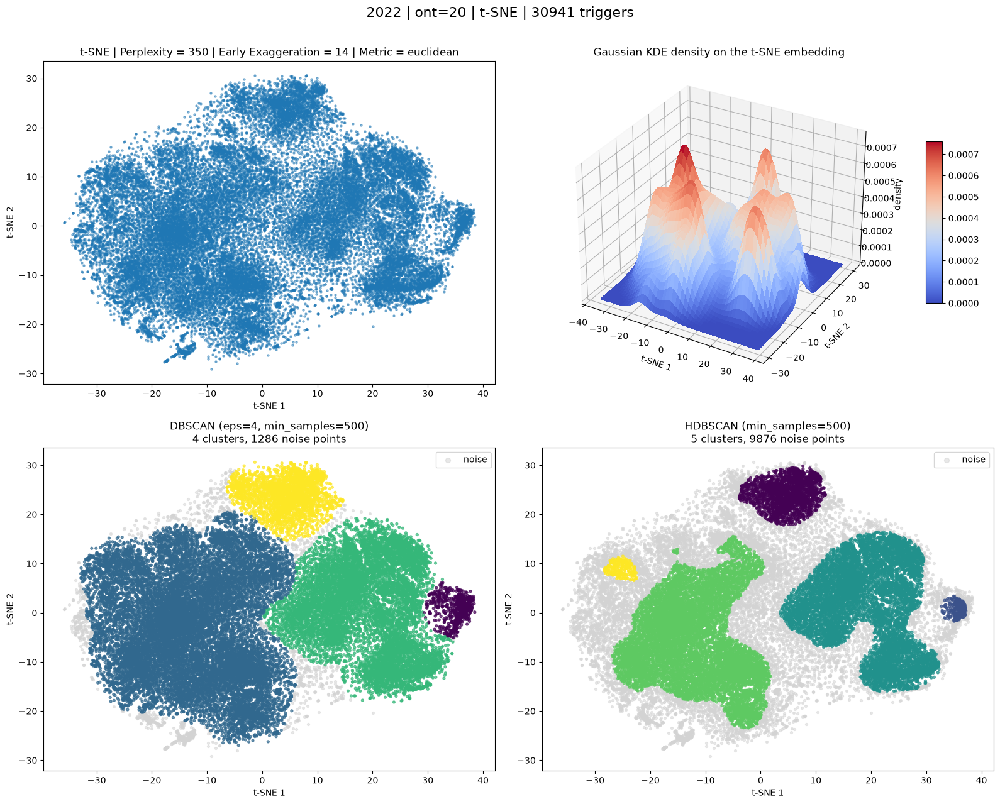

2022 ont=20 t-SNE: DBSCAN 4 clusters / 1286 noise, HDBSCAN 5 clusters / 9876 noise


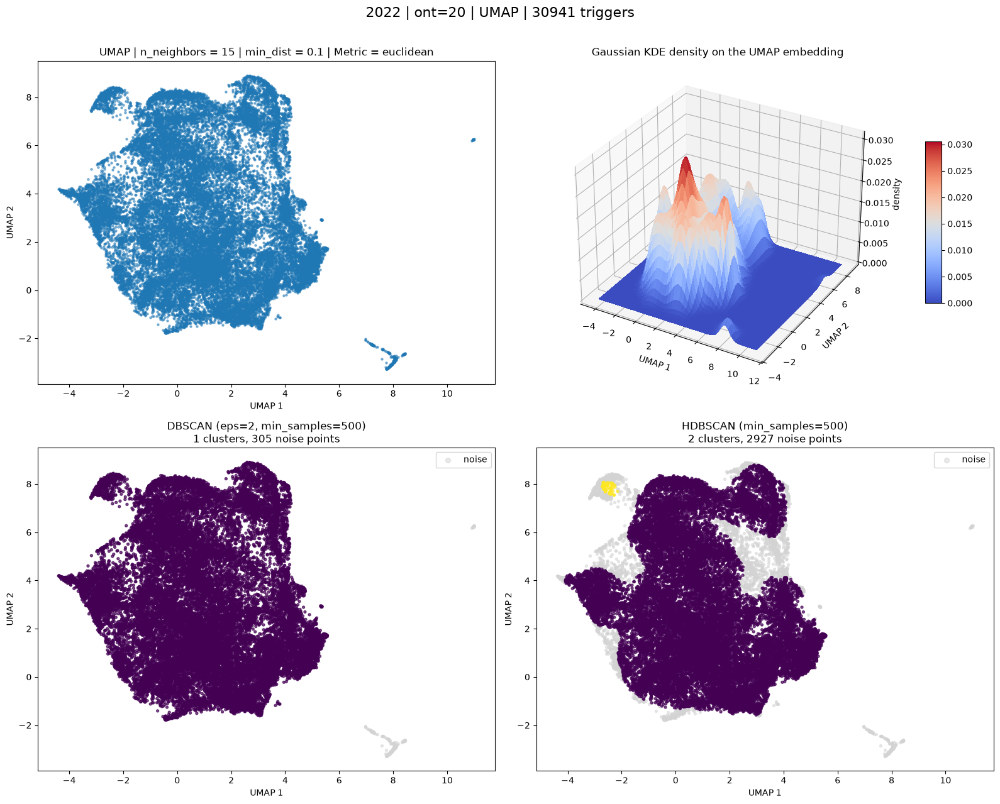

2022 ont=20 UMAP: DBSCAN 1 clusters / 305 noise, HDBSCAN 2 clusters / 2927 noise
2022 ont=20: 30941 triggers, 1230 features
2022 ont=20: computing t-SNE ...
2022 ont=20: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


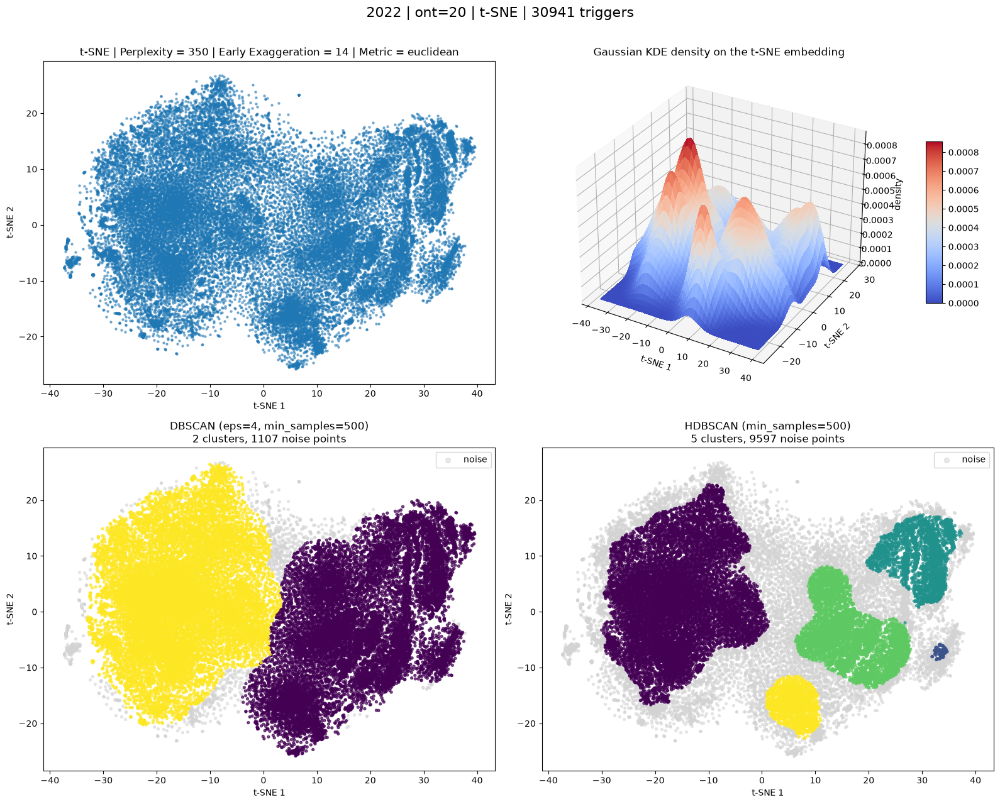

2022 ont=20 t-SNE: DBSCAN 2 clusters / 1107 noise, HDBSCAN 5 clusters / 9597 noise


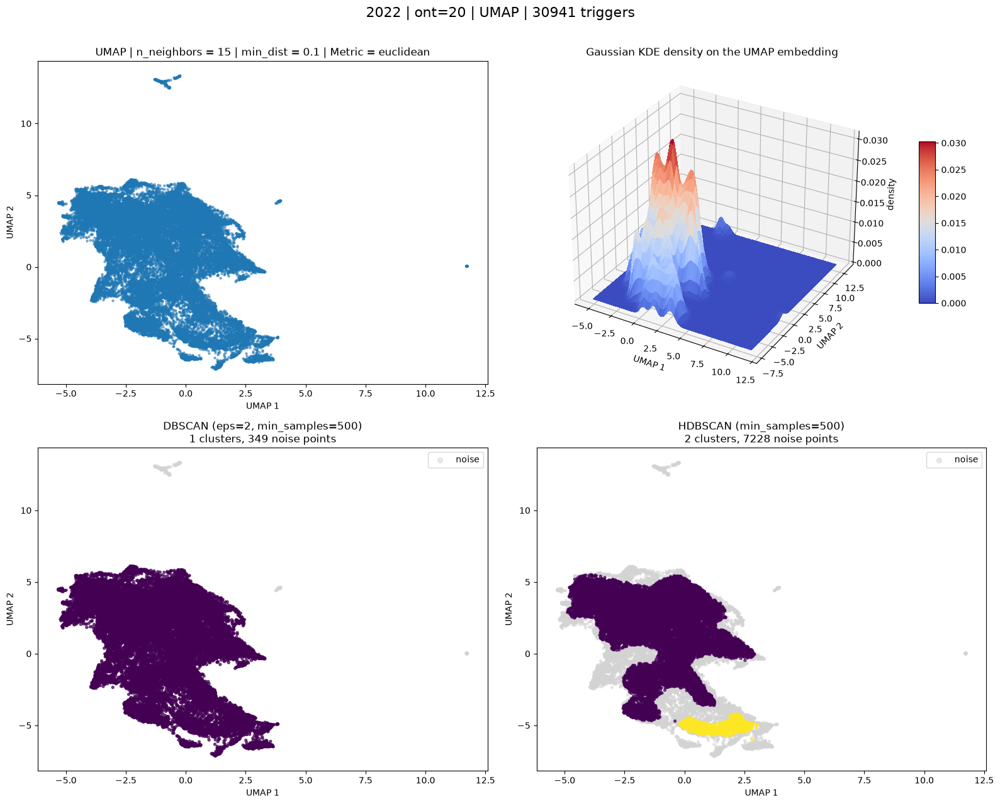

2022 ont=20 UMAP: DBSCAN 1 clusters / 349 noise, HDBSCAN 2 clusters / 7228 noise
2022 ont=25: 21251 triggers, 1230 features
2022 ont=25: computing t-SNE ...
2022 ont=25: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


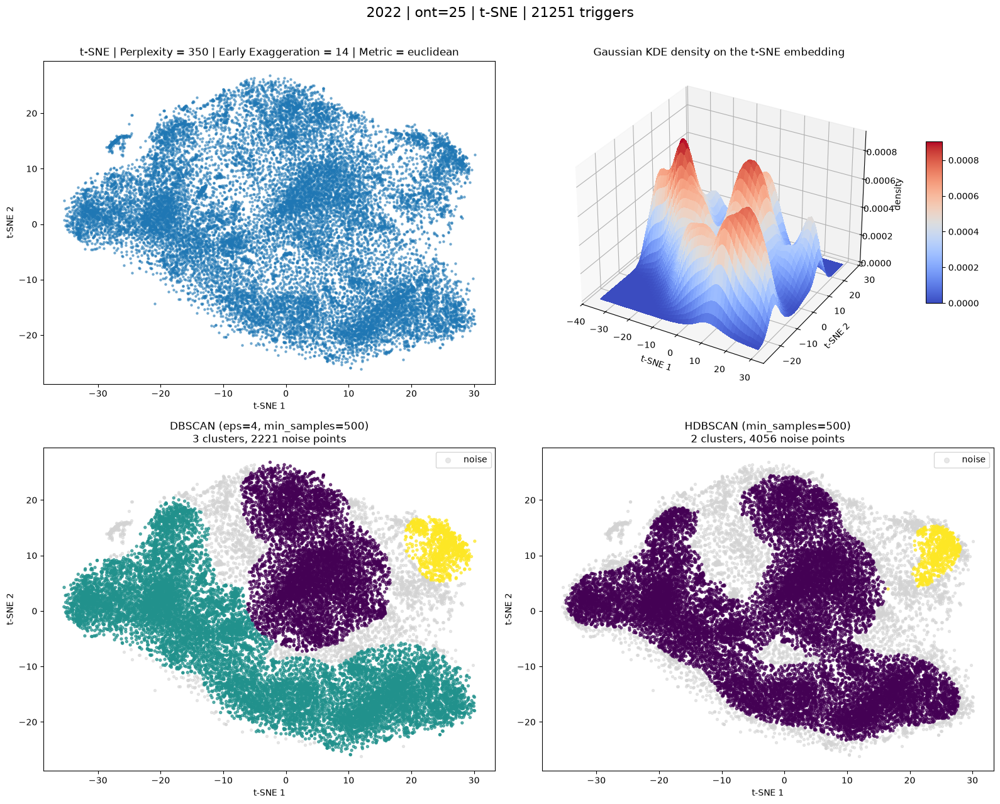

2022 ont=25 t-SNE: DBSCAN 3 clusters / 2221 noise, HDBSCAN 2 clusters / 4056 noise


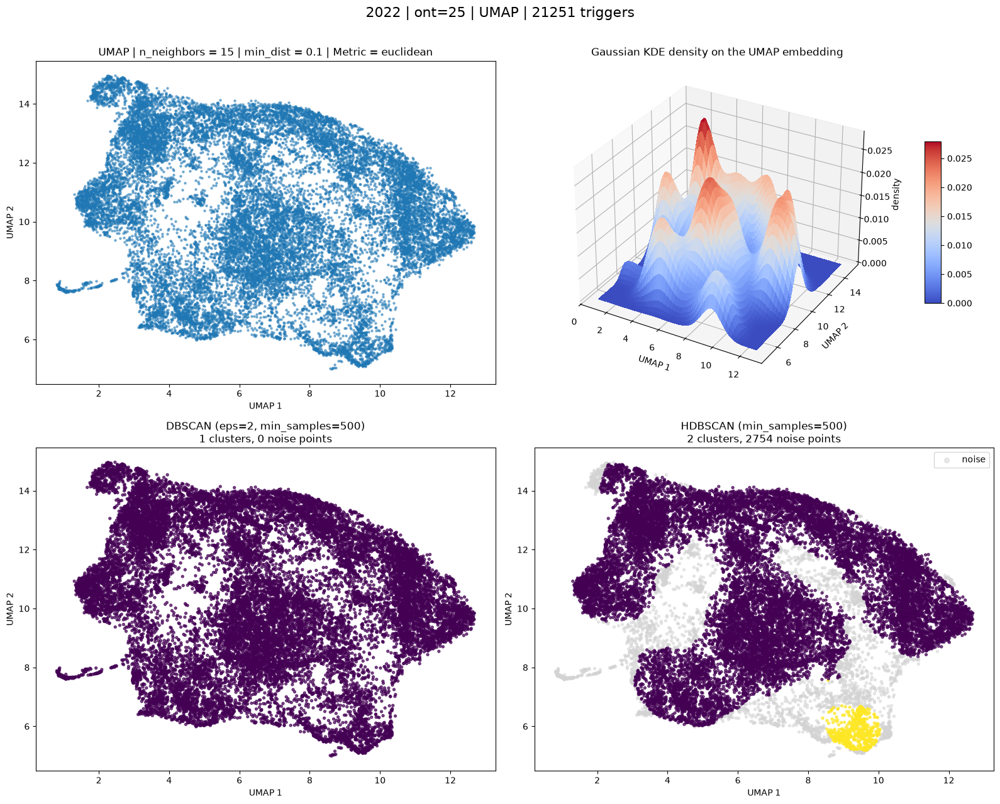

2022 ont=25 UMAP: DBSCAN 1 clusters / 0 noise, HDBSCAN 2 clusters / 2754 noise
2022 ont=25: 21251 triggers, 1230 features
2022 ont=25: computing t-SNE ...
2022 ont=25: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


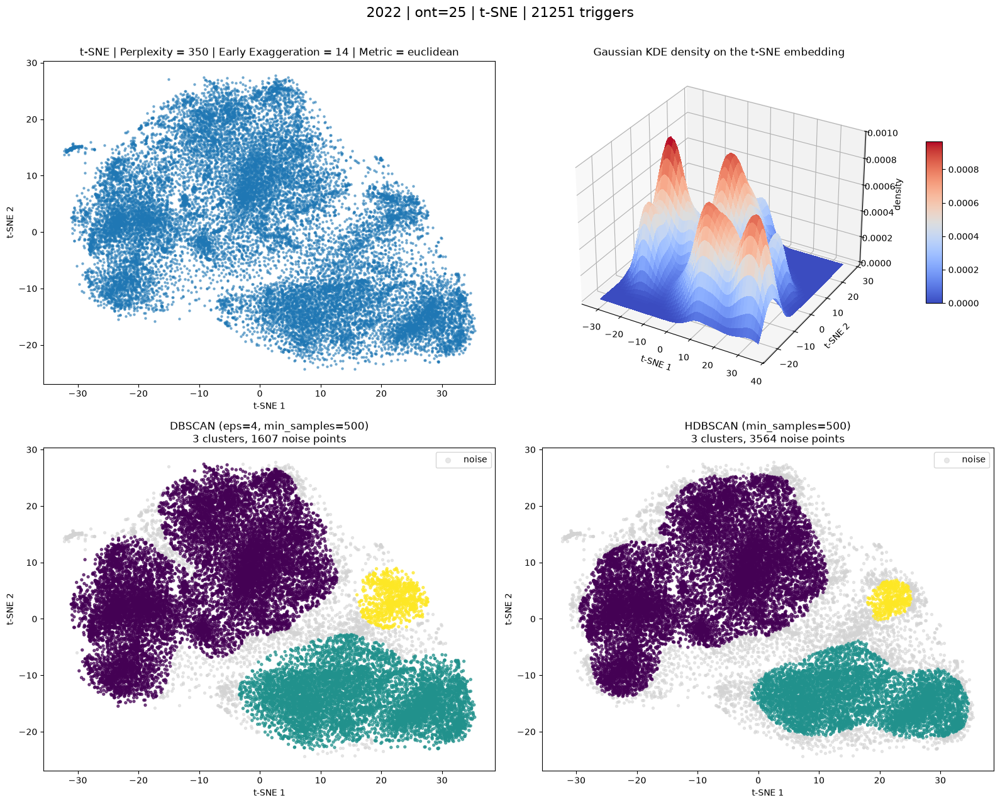

2022 ont=25 t-SNE: DBSCAN 3 clusters / 1607 noise, HDBSCAN 3 clusters / 3564 noise


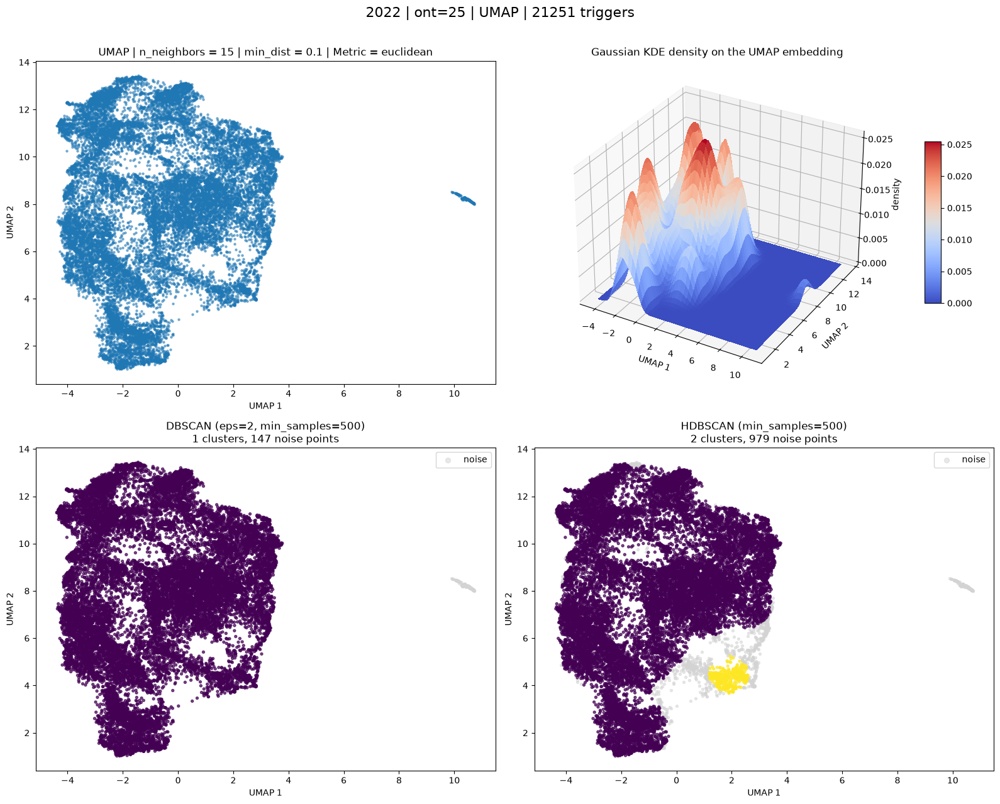

2022 ont=25 UMAP: DBSCAN 1 clusters / 147 noise, HDBSCAN 2 clusters / 979 noise
2022 ont=25: 21251 triggers, 1230 features
2022 ont=25: computing t-SNE ...
2022 ont=25: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


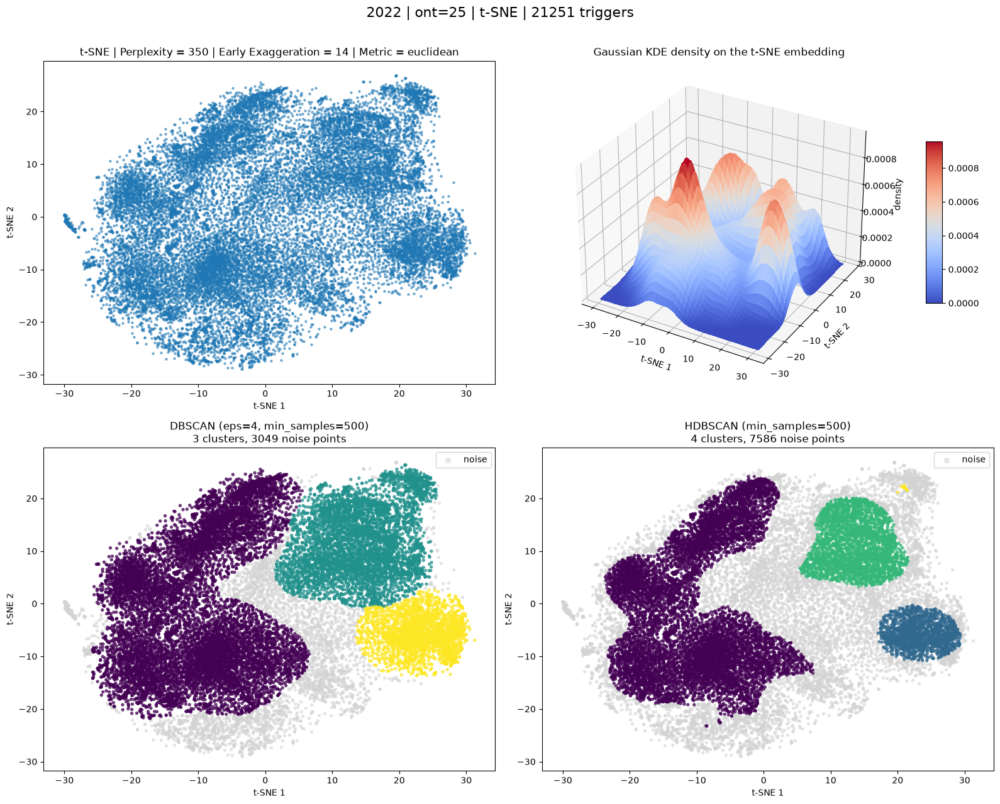

2022 ont=25 t-SNE: DBSCAN 3 clusters / 3049 noise, HDBSCAN 4 clusters / 7586 noise


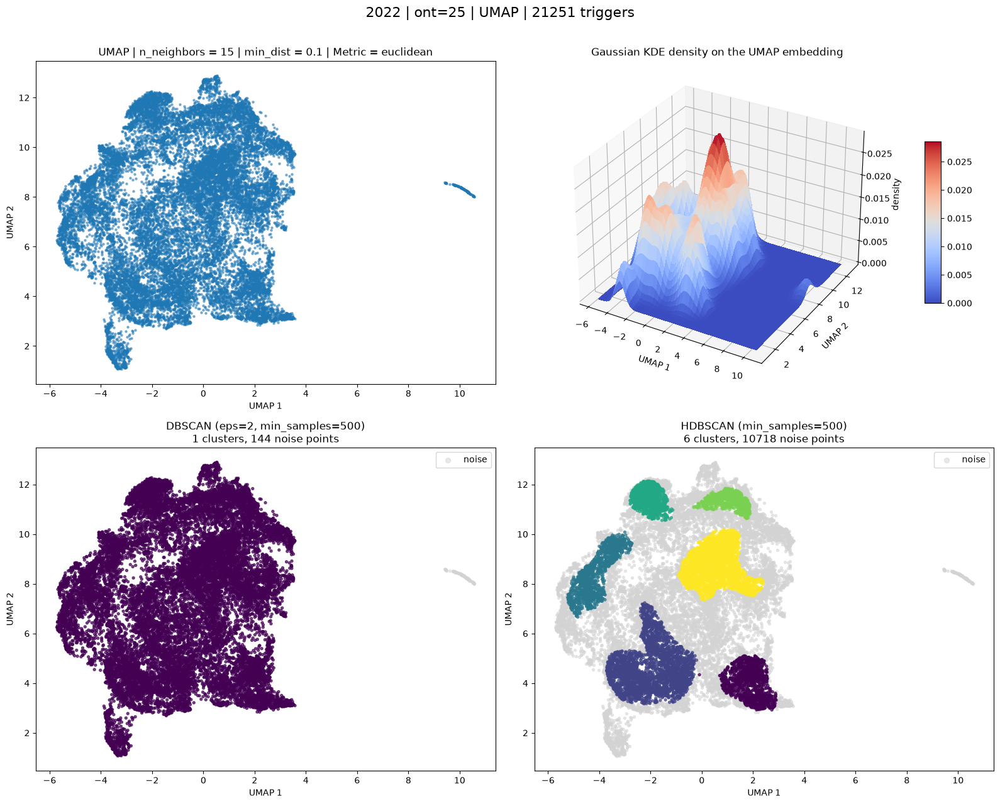

2022 ont=25 UMAP: DBSCAN 1 clusters / 144 noise, HDBSCAN 6 clusters / 10718 noise
2022 ont=25: 21251 triggers, 1230 features
2022 ont=25: computing t-SNE ...
2022 ont=25: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


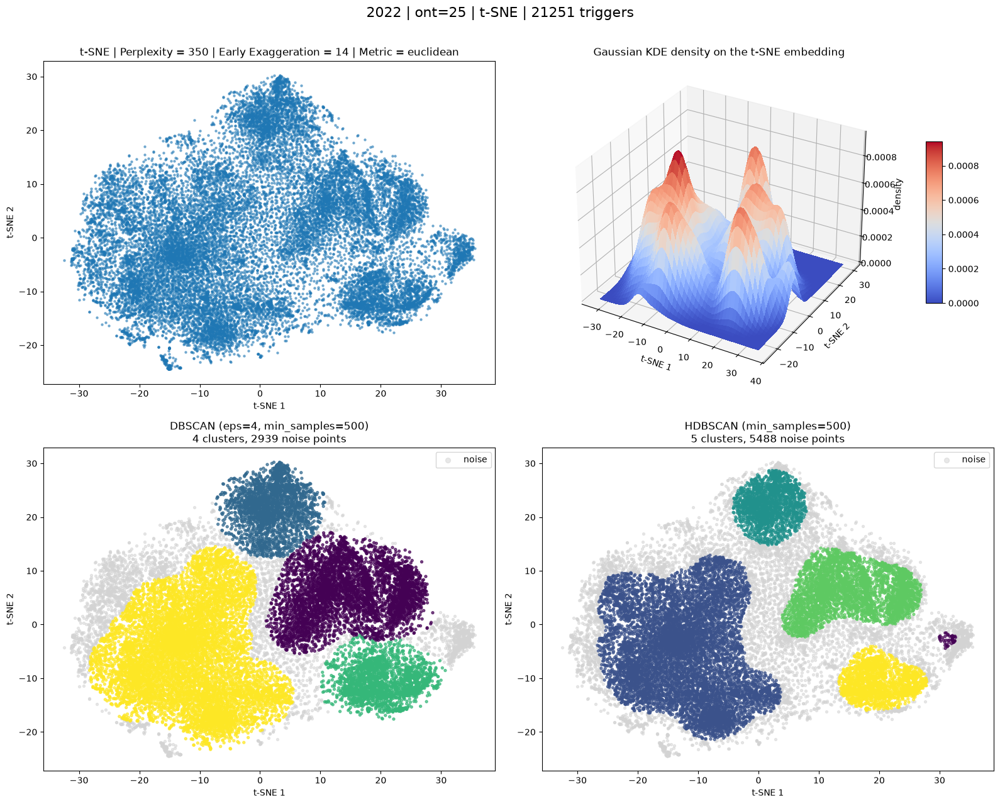

2022 ont=25 t-SNE: DBSCAN 4 clusters / 2939 noise, HDBSCAN 5 clusters / 5488 noise


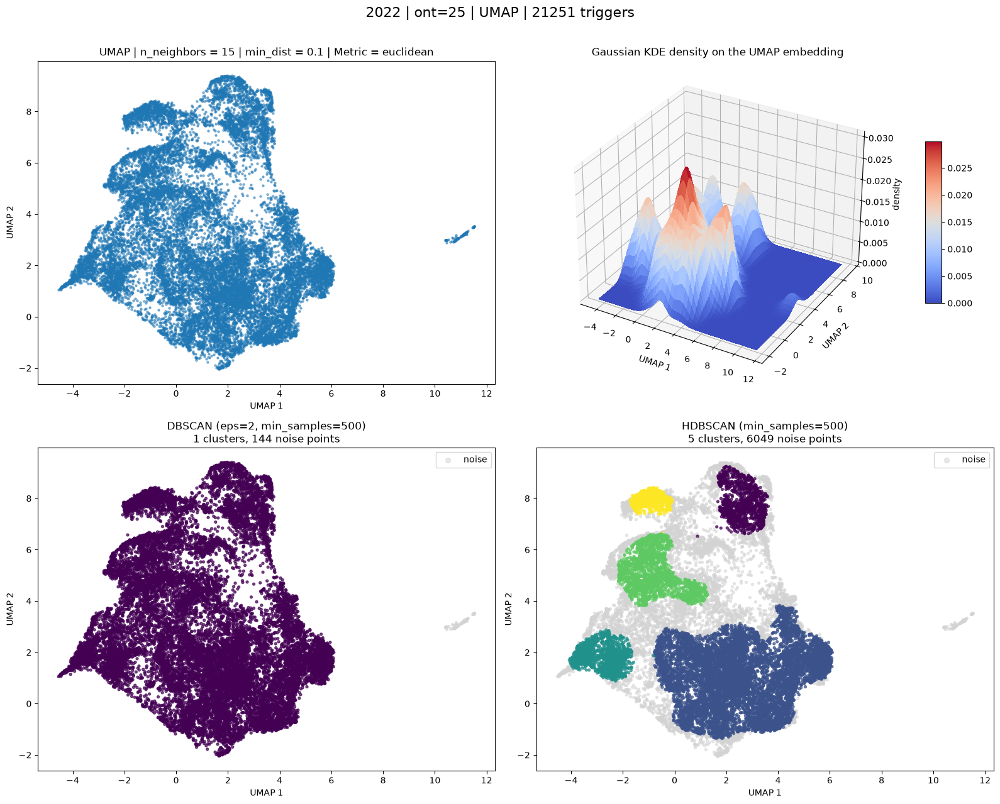

2022 ont=25 UMAP: DBSCAN 1 clusters / 144 noise, HDBSCAN 5 clusters / 6049 noise
2022 ont=25: 21251 triggers, 1230 features
2022 ont=25: computing t-SNE ...
2022 ont=25: computing UMAP ...


/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


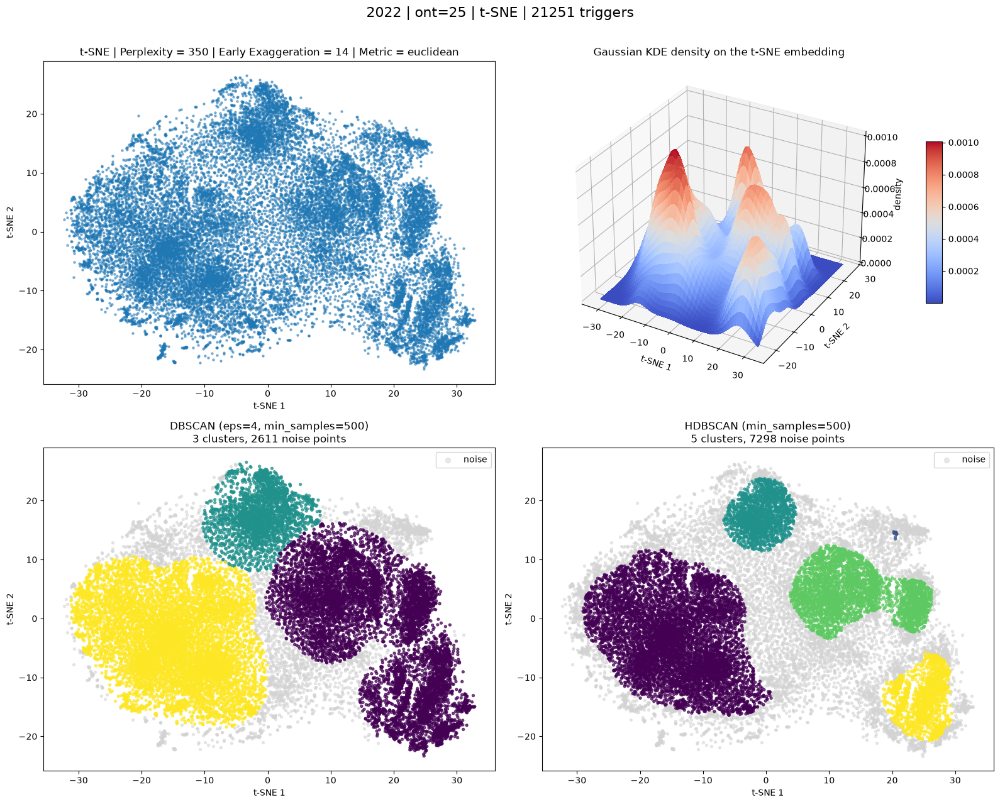

2022 ont=25 t-SNE: DBSCAN 3 clusters / 2611 noise, HDBSCAN 5 clusters / 7298 noise


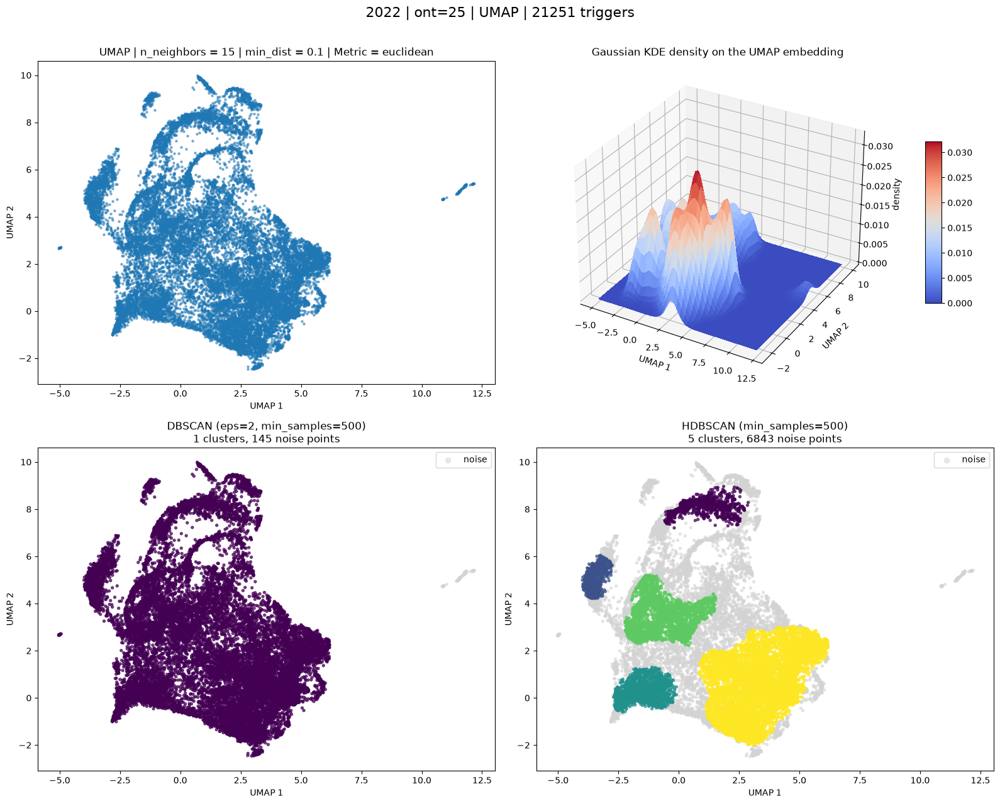

2022 ont=25 UMAP: DBSCAN 1 clusters / 145 noise, HDBSCAN 5 clusters / 6843 noise


In [8]:
for year in YEARS:
    for ont in ONTS:
        for hw in HW:
            run(year, ont, hw)